In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "3"

import scanpy as sc
import seaborn as sns
from tqdm import tqdm
import scanpy.external as sce

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import autocast, GradScaler

from Henosis.dataprocess.h5a import H5ADTokenizer
from Henosis.const import set_species_context
from Henosis import data
import Henosis.resa as resa
import Henosis.utils as utils
import Henosis.mmd as mmd
import Henosis.lr_schedule as lr_sche
import Henosis.swav as swav
import Henosis.peak_student as peak_student
import Henosis.henosis as henosis
torch.manual_seed(3407)

In [2]:
organ='pbmc10'
embed_org='pbmc10_ntv3_pre0'
species_to_adata={
    'homo_sapiens_atac':sc.read_h5ad(f'/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/scrna/{organ}/homo_sapiens_atac.h5ad'),
    'homo_sapiens_rna':sc.read_h5ad(f'/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/scrna/{organ}/homo_sapiens_rna.h5ad'),
}

In [3]:
species_to_embed_file = {
    "homo_sapiens_atac": f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/{embed_org}/homo_sapiens_atac.avg.embeddings",
    "homo_sapiens_rna": f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/{embed_org}/homo_sapiens_rna.avg.embeddings",
}

In [4]:
species_dict=set_species_context(species_to_adata)
token_species_dict={v: k for k, v in species_dict.items()}

In [5]:
tokenized = H5ADTokenizer(
    species_to_adata,
    species_to_embed_file,
).process_species_adata()
species_to_reps = {
    "homo_sapiens_atac": "X_lsi",
    "homo_sapiens_rna": "X_pca",
}
train_loader, test_loader = data.prepare_multispecies_dataloaders(
    tokenized,
    batch_size=512,
    species_to_reps=species_to_reps,
    batch_species=2,
)

100%|██████████| 11852/11852 [00:00<00:00, 28658.42it/s]


homo_sapiens_atac: X_lsi
homo_sapiens_rna: X_pca


In [6]:
embed_size=1536
d_model=120
latent_size=64
num_layers=1
#net=peak_student.BtacDDPSwAV(species_to_embed_file,d_model,embed_size,latent_size,num_layers,10000,1,modality="atac",species_mapping=species_dict)
net=henosis.Henosis(species_to_embed_file,d_model,embed_size,latent_size,encoder_type='set',species_mapping=species_dict)

PCA ing
PCA done


In [7]:
def train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,current_temp,scheduler,ml_weight=1.0):
    net.train()
    metrics=utils.Accumulator(4)
    pbar=tqdm(train_loader,desc='Processing')
    for _,batch in enumerate(pbar):
        optimizer.zero_grad(set_to_none=True)

        input_ids,adata,sp=batch
        input_ids = input_ids.to(device, non_blocking=True)
        adata = adata.float().to(device, non_blocking=True)
        sp = sp.to(device, non_blocking=True)
        '''modality=[token_species_dict[int(s)] for s in sp]
        modality=[int(m.split('_')[-1]=='atac') for m in modality]
        modality=torch.tensor(modality,device=device)'''

        with autocast('cuda'):
            sl = torch.tensor(0.0, device=device)
            protein_features,gene_features,logit_scales=net(adata,input_ids,sp,)
            species_ids = torch.unique(sp).tolist()
            #for i in torch.unique(sp):
            for s in species_ids:
                mask = (sp == s)

                indices = torch.nonzero(mask).squeeze(1)
                gene_features_i = torch.index_select(gene_features, 0, indices)
                protein_features_i=torch.index_select(protein_features, 0, indices)

                sl += loss_fn(protein_features_i, gene_features_i,logit_scales[int(s)])
            
            #ml=loss_fn1(protein_features,sp)
            ml=loss_fn1(protein_features,sp)
            loss=sl+ml*ml_weight

        scaler.scale(loss).backward()
        if net.transformer.embed.gene_embed.weight.grad is not None:
            #net.transformer.embed.gene_embed.weight.grad[3:-1] = 0
            net.transformer.embed.gene_embed.weight.grad[4:] = 0
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        if scheduler:
            scheduler.step()
        lr=optimizer.param_groups[0]['lr']
        pbar.set_description(f"loss:{loss.detach().item():.4f},sl:{sl.detach().item():.8f},ml:{ml.detach().item():.8f},lr:{lr:.8f}")
        metrics.add(loss.detach().item() * len(sp), sl.detach().item() * len(sp),ml.detach().item() * len(sp), len(sp))

    return {'loss':metrics[0] / metrics[3],'sl':metrics[1] / metrics[3],'ml':metrics[2] / metrics[3],}

def train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp=0.2,ml_weight=1.0,warm_epoch=2):
    def init_weights(m):
        if type(m) == nn.Linear or type(m) == nn.Conv1d:
            nn.init.xavier_uniform_(m.weight)
    net.apply(init_weights)
    print('init done')

    device =torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('training on', device)
    net.to(device)

    loss_fn=swav.MultiScaleATACKNNLoss()#swav.SwAVLoss()#swav.WeightedMultiScaleATACKNNLoss()#swav.ATACKNNLoss()#
    loss_fn1=mmd.MMMD(kernel_type='rbf',each=True)#mmd.MSampleLoss(each=True)#
    optimizer = torch.optim.AdamW(net.parameters(), lr=lr,fused=True)
    scheduler = lr_sche.CosineAnnealingWarmupRestarts(
        optimizer,
        first_cycle_steps=2000,   # 一个周期 2000 batch
        cycle_mult=1,             # 不增加周期长度
        max_lr=lr*1.5,            # 最大 lr 稍高
        min_lr=1e-6,
        warmup_steps=400,         # 前 400 batch 线性升到 max_lr
        gamma=0.6
    )
    early_stopping = utils.EarlyStopping(
        patience=10,               # 连续5个epoch指标不提升就停止
        verbose=True, 
        path=net_path, # 保存的文件名
        mode='min'                # 如果监控的是准确率，这里改用 'max'
    )
    scaler = GradScaler('cuda')
    cr_ml_weight=0.0
    try:
        for epoch in range(epochs):
            print(f"epoch:{epoch},")
            print(f"Temp: {temp}")
            if epoch>=warm_epoch:
                cr_ml_weight=ml_weight
            losses=train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,temp,scheduler,cr_ml_weight)
            current_lr = optimizer.param_groups[0]['lr']
            print(f"lr:{current_lr},")
            print(f'{losses}')
            for species in species_dict:
                print(species,net.logit_scales[species].cpu().detach().numpy())
            
            if epoch>=warm_epoch:
                early_stopping(losses['loss'],net)
                if early_stopping.early_stop:
                    print("====== Early stopping triggered! ======")
                    #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
                    break
            if epoch ==epochs-1:
                torch.save(net.state_dict(), net_path)
                print(f'saving weight in {net_path}')
                #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
                break
    except KeyboardInterrupt:
        #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
        torch.save(net.state_dict(), net_path)
        print(f'saving weight in {net_path}')

In [8]:
net_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/pth/ReSA_{organ}1_{embed_org}.pth'
species_to_h5=tokenized
epochs=100
lr=1e-3
train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp=0.0,ml_weight=1.0,warm_epoch=2)

init done
training on cuda
epoch:0,
Temp: 0.0


loss:10.0150,sl:10.01500702,ml:4.50177956,lr:0.00025958: 100%|██████████| 69/69 [00:05<00:00, 12.03it/s]


lr:0.00025957750000000005,
{'loss': 10.563898832901664, 'sl': 10.563898832901664, 'ml': 4.742812495300735}
homo_sapiens_atac 2.661926
homo_sapiens_rna 2.6624742
epoch:1,
Temp: 0.0


loss:9.1258,sl:9.12579346,ml:2.85332322,lr:0.00051816: 100%|██████████| 69/69 [00:05<00:00, 12.80it/s]  


lr:0.0005181550000000001,
{'loss': 9.624095087466033, 'sl': 9.624095087466033, 'ml': 3.6047717073689336}
homo_sapiens_atac 2.6596124
homo_sapiens_rna 2.6664908
epoch:2,
Temp: 0.0


...

lr:0.0008938999511008347,
{'loss': 7.348745041999264, 'sl': 7.276770260023034, 'ml': 0.07197478543157163}
homo_sapiens_atac 2.4013379
homo_sapiens_rna 2.716794
EarlyStopping counter: 8 out of 10
epoch:36,
Temp: 0.0


loss:7.3482,sl:7.27634335,ml:0.07183313,lr:0.00087987: 100%|██████████| 69/69 [00:05<00:00, 12.37it/s]


lr:0.0008798686147421361,
{'loss': 7.339189681453981, 'sl': 7.265914156817008, 'ml': 0.07327552463697351}
homo_sapiens_atac 2.4033508
homo_sapiens_rna 2.7115095
EarlyStopping counter: 9 out of 10
epoch:37,
Temp: 0.0


loss:7.4460,sl:7.37594891,ml:0.07000995,lr:0.00085797: 100%|██████████| 69/69 [00:05<00:00, 12.57it/s]

lr:0.0008579682001907794,
{'loss': 7.3094926295073135, 'sl': 7.2382950160814366, 'ml': 0.07119761342587679}
homo_sapiens_atac 2.4071016
homo_sapiens_rna 2.707583
EarlyStopping counter: 10 out of 10
====== Early stopping triggered! ======


infering: 100%|██████████| 47/47 [00:01<00:00, 25.88it/s]


computing PCA
    with n_comps=25


/mnt/public5/panguanyu/environment/mconda3/miniconda3/envs/crs_env/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


    finished (0:00:00)
Running MOT_Correction by 'species' -> adata.obsm['X_mot']
X_mot shape: (23761, 25)
computing neighbors


/mnt/public5/panguanyu/environment/mconda3/miniconda3/envs/crs_env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:40)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:20)


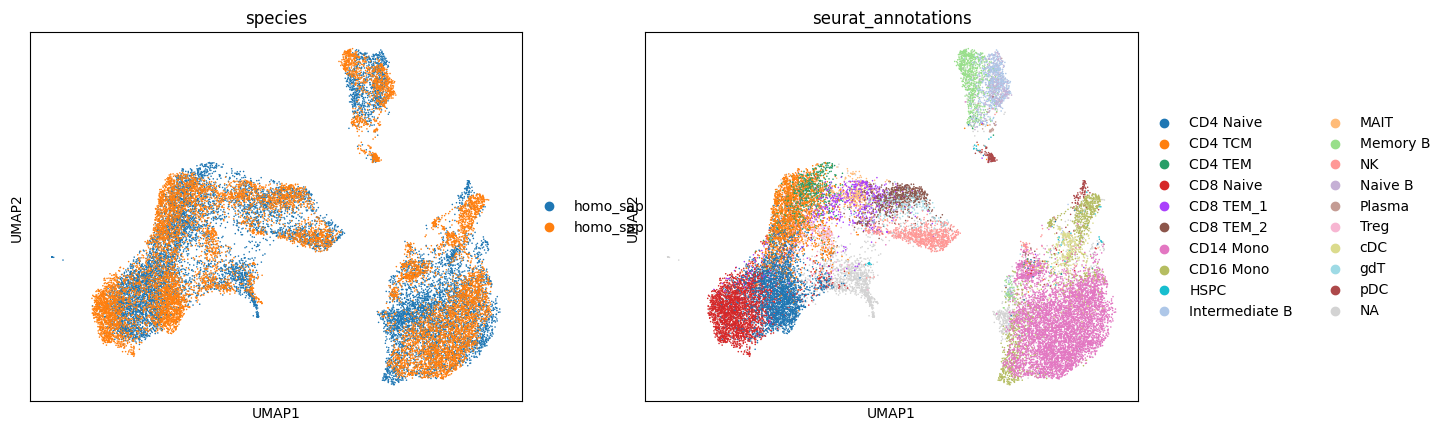

: 

In [ ]:
import importlib
import Henosis.evaluate
importlib.reload(Henosis.evaluate)
from Henosis.evaluate import evaluate_integration

integrated_adata = evaluate_integration(
    net,
    test_loader,
    species_to_adata=tokenized,
    metadata_columns=["seurat_annotations"],
    # 如果不同物种列名不一样，改用：
    #species_to_metadata_columns={
         #"one":["celltype"],
         #"homo_sapiens": ["coarse_cluster",],
         #"Sus_scrofa": ["cluster", ],
         #"Macaca_mulatta": ["cluster", ],
    #},
    embedding="protein",
    use_mot_correction=True,
    correction_by="species",
    correction_kwargs={
        "max_rounds": 10,
        "n_clusters": 100,
        "assignment_mode": "sinkhorn",
    },
    umap_colors=["species", "seurat_annotations"],
)
